# 03 — Individual building detection results

            This notebook reports independent auditorium, hospital and office detection experiments, followed by a matched comparison with pooled training. Each comparison uses the same target-building test rows and training-fold preprocessing.

            The normal-range rule is the transparent within-building reference included in the model runner. The pooled majority-class and actuator/pump-only baselines are reported in Notebook 02 because they are pooled reference baselines. The final section tests whether adding other buildings' training data improves an individual building model.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid')
COLORS = {'normal': '#457b9d', 'fault': '#e76f51', 'accent': '#2a9d8f', 'dark': '#264653'}

def find_root():
    for candidate in [Path.cwd(), Path.cwd().parent, Path('/Users/mili/Desktop/IRPN')]:
        if (candidate / 'pyproject.toml').exists() and (candidate / 'results').exists():
            return candidate
    raise FileNotFoundError('Open this notebook from the IRPN repository or set ROOT manually.')

ROOT = find_root()

def read_json(path):
    return json.loads(path.read_text(encoding='utf-8'))

def require(*paths):
    missing = [str(path) for path in paths if not path.exists()]
    if missing:
        raise FileNotFoundError('Missing saved artefacts. Run the pipeline commands first:\n' + '\n'.join(missing))

def pct(value):
    return f'{100 * value:.1f}%' if pd.notna(value) else 'n/a'

## 1. Load the independent building artefacts

In [2]:
RESULTS = ROOT / 'results' / 'building_specific'
CLEANED = ROOT / 'data' / 'interim' / 'cleaned' / 'cleaned_ahu.csv'
require(
    RESULTS / 'building_detection_manifest.json',
    RESULTS / 'building_detection_validation_metrics.csv',
    RESULTS / 'building_detection_test_metrics.csv',
    RESULTS / 'building_detection_selected_models.csv',
    CLEANED,
)
manifest = read_json(RESULTS / 'building_detection_manifest.json')
validation = pd.read_csv(RESULTS / 'building_detection_validation_metrics.csv')
test = pd.read_csv(RESULTS / 'building_detection_test_metrics.csv')
selected = pd.read_csv(RESULTS / 'building_detection_selected_models.csv')
cleaned = pd.read_csv(CLEANED, low_memory=False)
print('Buildings:', manifest.get('buildings'))
print('Models requested:', manifest.get('models_requested'))
print('Selection metric:', manifest.get('selection_metric'))

Buildings: ['auditorium', 'hospital', 'office']
Models requested: ['normal_range_rule', 'isolation_forest', 'xgboost', 'lstm_autoencoder']
Selection metric: f1


## 2. Building support and label balance

In [3]:
is_normal = cleaned['label'].astype('string').str.contains('Normal', case=False, na=False)
support = cleaned.assign(is_normal=is_normal).groupby('building').agg(
    rows=('building', 'size'),
    ahus=('ahu', 'nunique'),
    normal_rows=('is_normal', 'sum'),
    fault_rows=('is_normal', lambda values: int((~values).sum())),
).reset_index()
display(support)

,building,rows,ahus,normal_rows,fault_rows
0,auditorium,113375,13,60219,53156
1,hospital,65680,8,53491,12189
2,office,175532,20,119402,56130


## 3. Model validation comparison

In [4]:
validation_view = validation[['building', 'design', 'fold', 'model', 'f1', 'balanced_accuracy', 'false_positive_rate', 'coverage']]
display(validation_view.sort_values(['building', 'design', 'f1'], ascending=[True, True, False]).round(3))

,building,design,fold,model,f1,balanced_accuracy,false_positive_rate,coverage
2,auditorium,building_ahu_held_out,fold_001,xgboost,0.999,0.999,0.000,1.000
0,auditorium,building_ahu_held_out,fold_001,normal_range_rule,0.711,0.738,0.145,1.000
1,auditorium,building_ahu_held_out,fold_001,isolation_forest,0.057,0.507,0.016,1.000
3,auditorium,building_ahu_held_out,fold_001,lstm_autoencoder,0.042,0.504,0.014,0.991
6,auditorium,building_chronological,fold_001,xgboost,0.996,0.997,0.004,1.000
4,auditorium,building_chronological,fold_001,normal_range_rule,0.718,0.773,0.143,1.000
5,auditorium,building_chronological,fold_001,isolation_forest,0.065,0.516,0.002,1.000
7,auditorium,building_chronological,fold_001,lstm_autoencoder,0.022,0.504,0.003,0.994
10,hospital,building_ahu_held_out,fold_001,xgboost,0.789,0.937,0.018,1.000
9,hospital,building_ahu_held_out,fold_001,isolation_forest,0.253,0.621,0.051,1.000


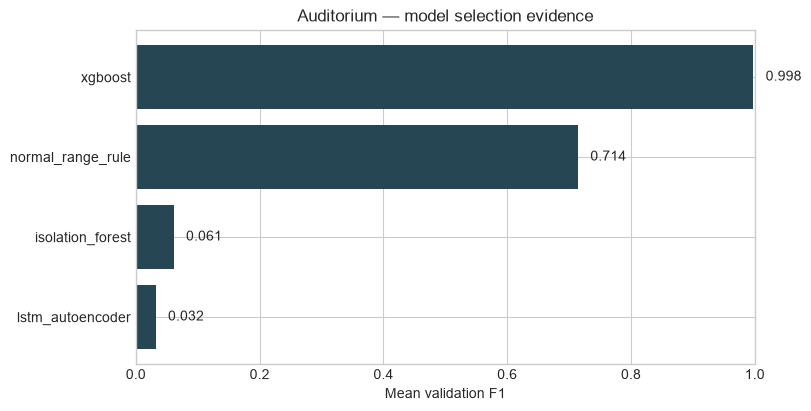

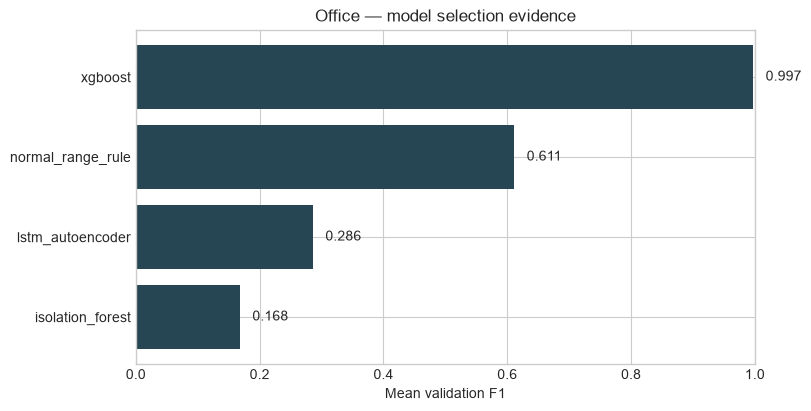

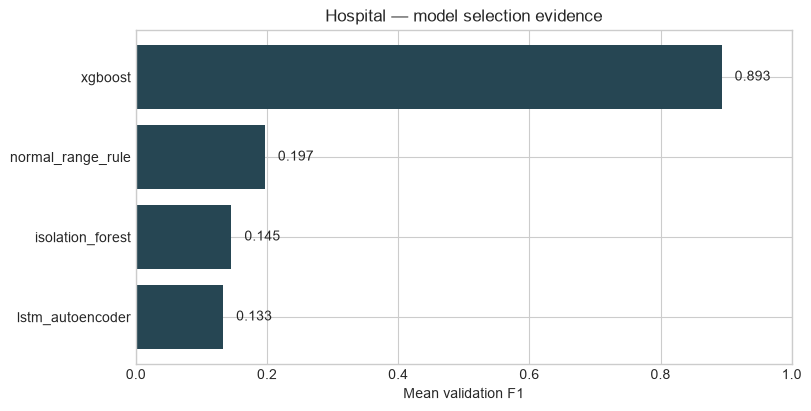

In [5]:
for building in ['auditorium', 'office', 'hospital']:
    plot_data = validation[validation['building'].eq(building)].groupby('model', as_index=False).agg(
        mean_f1=('f1', 'mean')
    ).sort_values('mean_f1')
    fig, ax = plt.subplots(figsize=(8, 4), constrained_layout=True)
    ax.barh(plot_data['model'], plot_data['mean_f1'], color=COLORS['dark'])
    ax.set_xlim(0, 1)
    ax.set_xlabel('Mean validation F1')
    ax.set_title(f'{building.title()} — model selection evidence')
    for index, value in enumerate(plot_data['mean_f1']):
        ax.text(value + 0.02, index, f'{value:.3f}', va='center')
    plt.show()

Validation performance is used to select a model separately for each building and split design. Test performance is not used for selection, so the final test rows remain an unbiased held-out estimate under the declared protocol.

## 4. Selected model and final held-out test results

In [6]:
display(selected.round(3))
test_view = test[['building', 'design', 'fold', 'model', 'f1', 'balanced_accuracy', 'precision', 'recall', 'false_positive_rate', 'coverage']]
display(test_view.round(3))

,building,design,fold,selected_model,selection_metric,validation_score,validation_balanced_accuracy,validation_coverage
0,auditorium,building_ahu_held_out,fold_001,xgboost,f1,0.999,0.999,1.0
1,auditorium,building_chronological,fold_001,xgboost,f1,0.996,0.997,1.0
2,hospital,building_ahu_held_out,fold_001,xgboost,f1,0.789,0.937,1.0
3,hospital,building_chronological,fold_001,xgboost,f1,0.997,0.997,1.0
4,office,building_ahu_held_out,fold_001,xgboost,f1,0.998,0.998,1.0
5,office,building_chronological,fold_001,xgboost,f1,0.997,0.997,1.0


,building,design,fold,model,f1,balanced_accuracy,precision,recall,false_positive_rate,coverage
0,auditorium,building_ahu_held_out,fold_001,xgboost,0.997,0.997,0.998,0.996,0.002,1.0
1,auditorium,building_chronological,fold_001,xgboost,1.000,1.000,1.000,1.000,0.000,1.0
2,hospital,building_ahu_held_out,fold_001,xgboost,0.077,0.507,0.613,0.041,0.028,1.0
3,hospital,building_chronological,fold_001,xgboost,0.880,0.958,0.814,0.959,0.043,1.0
4,office,building_ahu_held_out,fold_001,xgboost,0.997,0.997,1.000,0.995,0.000,1.0
5,office,building_chronological,fold_001,xgboost,0.996,0.997,0.997,0.995,0.001,1.0


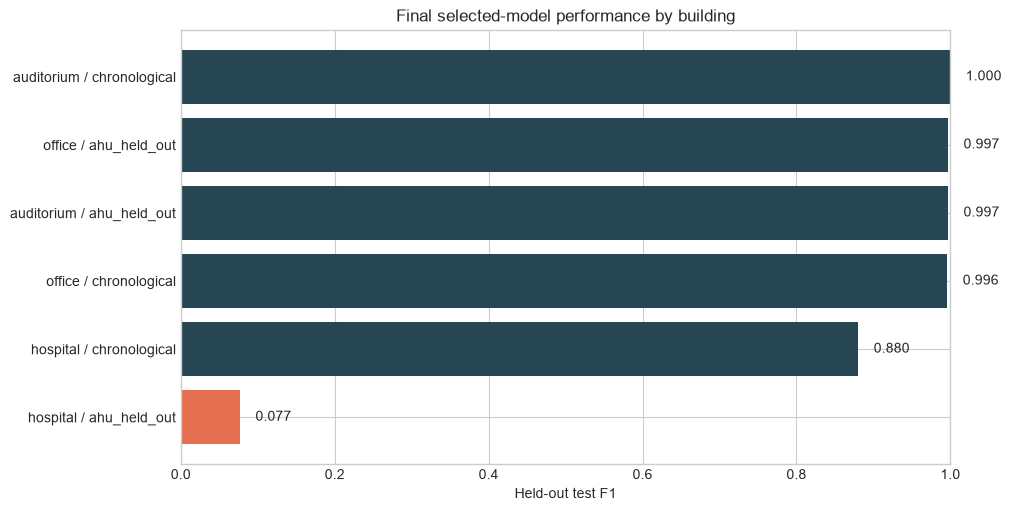

In [7]:
test_plot = test.copy()
test_plot['evaluation'] = test_plot['building'] + ' / ' + test_plot['design'].str.replace('building_', '', regex=False)
test_plot = test_plot.sort_values('f1')
fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)
ax.barh(test_plot['evaluation'], test_plot['f1'], color=[COLORS['fault'] if value < 0.7 else COLORS['dark'] for value in test_plot['f1']])
ax.set_xlim(0, 1)
ax.set_xlabel('Held-out test F1')
ax.set_title('Final selected-model performance by building')
for index, value in enumerate(test_plot['f1']):
    ax.text(value + 0.02, index, f'{value:.3f}', va='center')
plt.show()

## 5. Building-specific conclusions

In [8]:
interpretation = pd.DataFrame([
    ['Auditorium', 'XGBoost is selected for both designs and performs strongly on the held-out tests.', 'Evidence is specific to the auditorium data and split policies.'],
    ['Office', 'XGBoost is selected for both designs and performs strongly on the held-out tests.', 'Local performance does not prove transfer to another building.'],
    ['Hospital', 'The chronological result is materially stronger than the unseen-AHU result.', 'Hospital sensor availability and operating differences require local calibration.'],
], columns=['building', 'observed result', 'qualification'])
display(interpretation)

,building,observed result,qualification
0,Auditorium,XGBoost is selected for both designs and perfo...,Evidence is specific to the auditorium data an...
1,Office,XGBoost is selected for both designs and perfo...,Local performance does not prove transfer to a...
2,Hospital,The chronological result is materially stronge...,Hospital sensor availability and operating dif...


These are independent building models, not one pooled model evaluated three times. Their purpose is to test whether local calibration improves reliability and whether one building's data is masking another building's weaknesses. They complement, rather than replace, the pooled comparison in Notebook 02.

## 6. Matched pooled-versus-individual comparison

This is the fair comparison between deployment strategies. Every strategy is evaluated on the same held-out rows for a building and split. **Individual XGBoost** uses only that building's training rows. **Pooled-adapted XGBoost** adds the other buildings' training rows while retaining the target building's validation and test boundaries. **Pooled-transfer XGBoost** trains only on other buildings and represents a genuinely unseen-building transfer case.

In [9]:
MATCHED = ROOT / 'results' / 'matched_pooled_vs_individual'
require(
    MATCHED / 'matched_building_manifest.json',
    MATCHED / 'matched_building_validation_metrics.csv',
    MATCHED / 'matched_building_test_metrics.csv',
    MATCHED / 'matched_building_test_summary.csv',
    MATCHED / 'matched_building_test_row_checks.csv',
)
matched_manifest = read_json(MATCHED / 'matched_building_manifest.json')
matched_validation = pd.read_csv(MATCHED / 'matched_building_validation_metrics.csv')
matched_test = pd.read_csv(MATCHED / 'matched_building_test_metrics.csv')
matched_summary = pd.read_csv(MATCHED / 'matched_building_test_summary.csv')
row_checks = pd.read_csv(MATCHED / 'matched_building_test_row_checks.csv')
assert row_checks['test_row_ids_match'].all(), 'The paired models do not share identical test rows.'
assert row_checks['strategy'].nunique() == 3
display(pd.DataFrame([matched_manifest['protocol']]).T.rename(columns={0: 'comparison rule'}))
display(row_checks[['building', 'design', 'test_rows', 'test_row_ids_match']].drop_duplicates().sort_values(['building', 'design']))

,comparison rule
individual,target-building training rows only; refit on t...
pooled_adapted,target-building training rows plus other-build...
pooled_transfer,other-building training rows only; target buil...
test_rows,identical target-building test row IDs for all...


,building,design,test_rows,test_row_ids_match
0,auditorium,building_ahu_held_out,26164,True
3,auditorium,building_chronological,22685,True
6,hospital,building_ahu_held_out,16420,True
9,hospital,building_chronological,13136,True
12,office,building_ahu_held_out,35102,True
15,office,building_chronological,35114,True


The test comparison below is the primary evidence. A higher F1 or balanced accuracy is useful only if it is not achieved by a materially higher false-positive rate.

In [10]:
matched_view = matched_test[['building', 'design', 'model', 'rows', 'f1', 'balanced_accuracy', 'recall', 'false_positive_rate', 'train_rows', 'train_buildings']]
display(matched_view.sort_values(['building', 'design', 'model']).round(3))

,building,design,model,rows,f1,balanced_accuracy,recall,false_positive_rate,train_rows,train_buildings
0,auditorium,building_ahu_held_out,individual_xgboost,26164,0.997,0.997,0.996,0.002,87211,auditorium
1,auditorium,building_ahu_held_out,pooled_adapted_xgboost,26164,0.999,0.999,1.000,0.002,225378,all_buildings
2,auditorium,building_ahu_held_out,pooled_transfer_xgboost,26164,0.276,0.580,0.160,0.000,138167,other_buildings
3,auditorium,building_chronological,individual_xgboost,22685,1.000,1.000,1.000,0.000,90690,auditorium
4,auditorium,building_chronological,pooled_adapted_xgboost,22685,0.996,0.996,0.992,0.000,235402,all_buildings
5,auditorium,building_chronological,pooled_transfer_xgboost,22685,0.275,0.580,0.159,0.000,144712,other_buildings
6,hospital,building_ahu_held_out,individual_xgboost,16420,0.077,0.507,0.041,0.028,49260,hospital
7,hospital,building_ahu_held_out,pooled_adapted_xgboost,16420,0.079,0.506,0.042,0.031,215635,all_buildings
8,hospital,building_ahu_held_out,pooled_transfer_xgboost,16420,0.070,0.498,0.038,0.041,166375,other_buildings
9,hospital,building_chronological,individual_xgboost,13136,0.880,0.958,0.959,0.043,52544,hospital


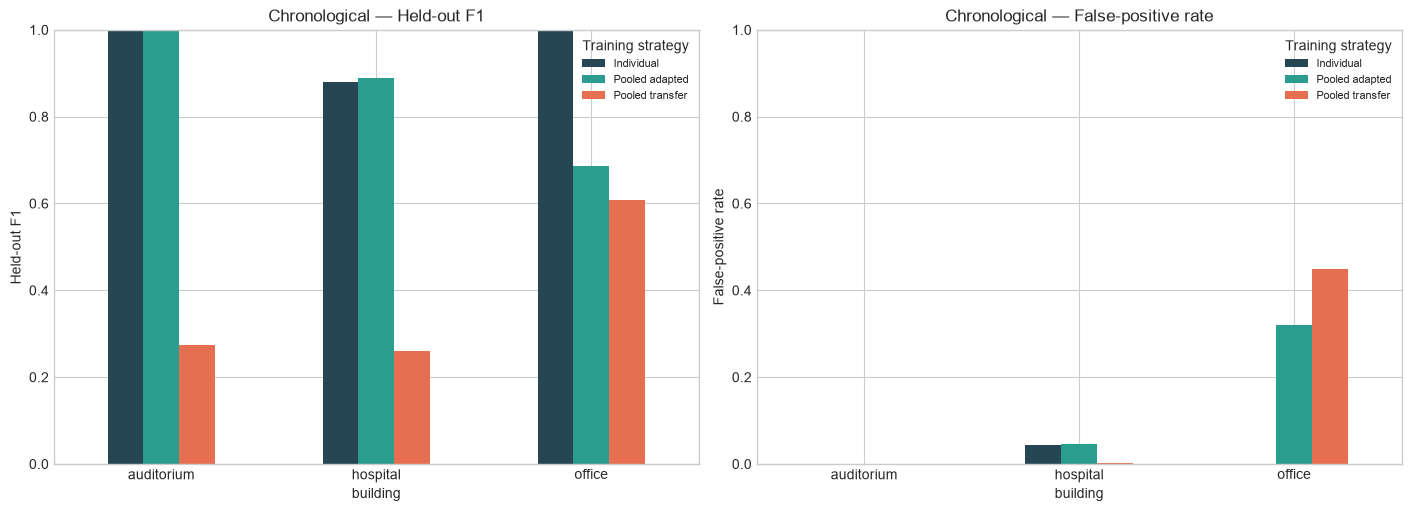

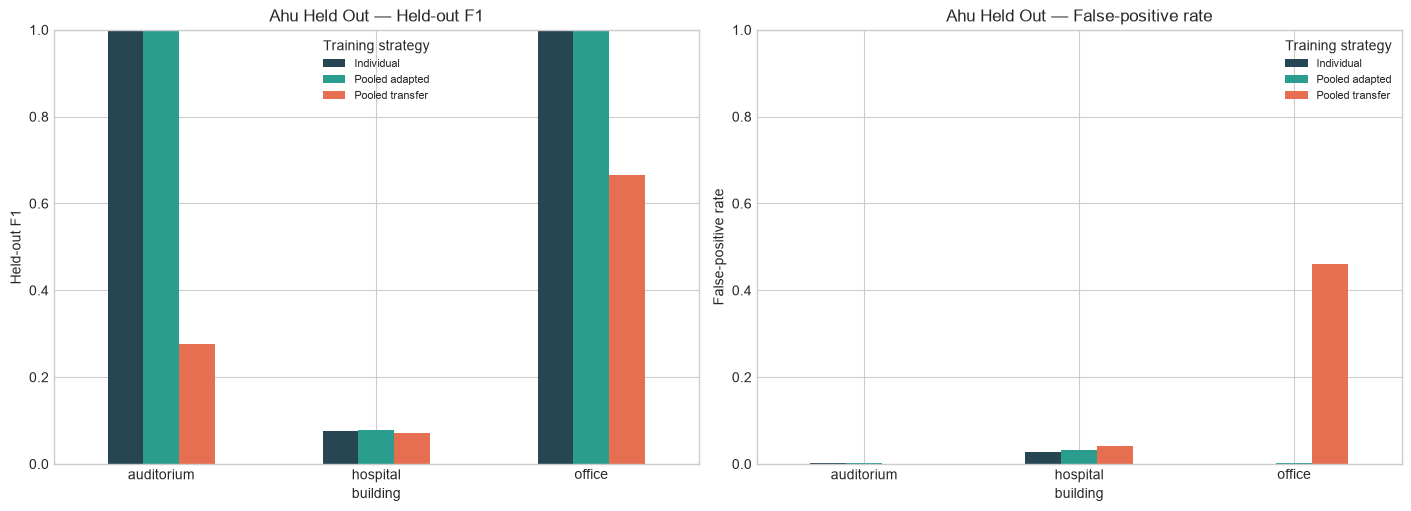

In [11]:
strategy_order = ['individual_xgboost', 'pooled_adapted_xgboost', 'pooled_transfer_xgboost']
strategy_labels = {
    'individual_xgboost': 'Individual',
    'pooled_adapted_xgboost': 'Pooled adapted',
    'pooled_transfer_xgboost': 'Pooled transfer',
}
for design in ['building_chronological', 'building_ahu_held_out']:
    plot_data = matched_test[matched_test['design'].eq(design)].copy()
    plot_data['strategy_label'] = plot_data['model'].map(strategy_labels)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
    for axis, metric, title in zip(axes, ['f1', 'false_positive_rate'], ['Held-out F1', 'False-positive rate'], strict=True):
        table = plot_data.pivot(index='building', columns='model', values=metric).reindex(columns=strategy_order)
        table.columns = [strategy_labels[column] for column in table.columns]
        table.plot.bar(ax=axis, color=[COLORS['dark'], COLORS['accent'], COLORS['fault']])
        axis.set_title(f'{design.replace("building_", "").replace("_", " ").title()} — {title}')
        axis.set_ylabel(title)
        axis.set_ylim(0, 1)
        axis.tick_params(axis='x', rotation=0)
        axis.legend(title='Training strategy', fontsize=8)
    plt.show()

The matched comparison answers a different question from the unseen-building transfer experiment. If the target building already has representative historical data, the individual and pooled-adapted results are the relevant comparison. Pooled-transfer performance describes a new building with no local labels and should not be used to justify a local deployment choice. The final recommendation should therefore be made per building using the chronological results as the main deployment evidence, with AHU-held-out results as a robustness check.